# 2.0 EDA on the training set: what drives iPhone asking prices

**Purpose.** Steps 10–14 of the data science lifecycle, done before any modelling: the price distribution, how each candidate input relates to price, overlap between inputs, missing values, and anything that sends us back to cleaning. Each section ends with a takeaway, and the summary lists what this means for the modelling steps.

**Data.** The **training set only**: 80% of the cleaned listings (`split.load_train()`). The 20% test set (`data/processed/test_listing_ids.csv`) is not looked at until the final evaluation, so nothing seen here can leak into the final score. The team's first look at all the data is in `1.0-eda.ipynb`.

**Rules this follows.** [docs/ml-plan.md](../docs/ml-plan.md): the target, metrics and which inputs are allowed were fixed before this notebook.

**How to run.** Select the `.venv` kernel, then *Run All*. It only reads data.

**Sections.** 1 Setup · 2 Price distribution (step 10) · 3 Outliers (step 10) · 4 Price vs each input (step 11) · 5 Overlap between inputs (step 12) · 6 Missing values (step 13) · 7 Back to cleaning? (step 14) · 8 Summary and decisions

## 1. Setup

**Relative price.** Model and storage explain most of the price, which hides everything else: retailers look expensive partly because they sell newer phones. To see the effect of condition, seller type, battery and so on *for the same phone*, most sections use the **relative price**: a listing's price divided by the median price of listings with the same model and storage. 1.00 means a typical price for that phone, 0.80 means 20% below typical.

Relative price is only computed where a model + storage combination has at least 5 listings, so the median it divides by is meaningful.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from priced_right.split import load_train

# Chart colours: one blue for single series, then a fixed order for several series
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
BLUE_GRAY_RED = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
sns.set_theme(style="whitegrid", rc={"grid.color": "#e6e5e1", "axes.edgecolor": "#c3c2b7"})
pd.set_option("display.max_columns", 30, "display.width", 140)

df = load_train()
print(f"training set: {len(df):,} listings, {df['exact_model'].nunique()} models")

# Relative price: price / median price of the same model + storage (groups of 5+ listings)
same_phone = df["exact_model"] + " | " + df["storage_gb"].astype(str)
group_size = df.groupby(same_phone)["price_eur"].transform("size")
df["rel_price"] = (df["price_eur"] / df.groupby(same_phone)["price_eur"].transform("median")).where(group_size >= 5)
print(f"relative price available for {df['rel_price'].notna().mean():.0%} of listings")

training set: 1,602 listings, 51 models
relative price available for 88% of listings


## 2. Price distribution (step 10)

**What:** the shape of the asking prices, before and after a log transform.
**Why:** a strongly skewed target makes models chase the few expensive phones, and it decides whether we train on price or log price (step 15).

median 250 €, mean 331 €, range 10–2299 €
skewness: price 1.57, log price -0.46


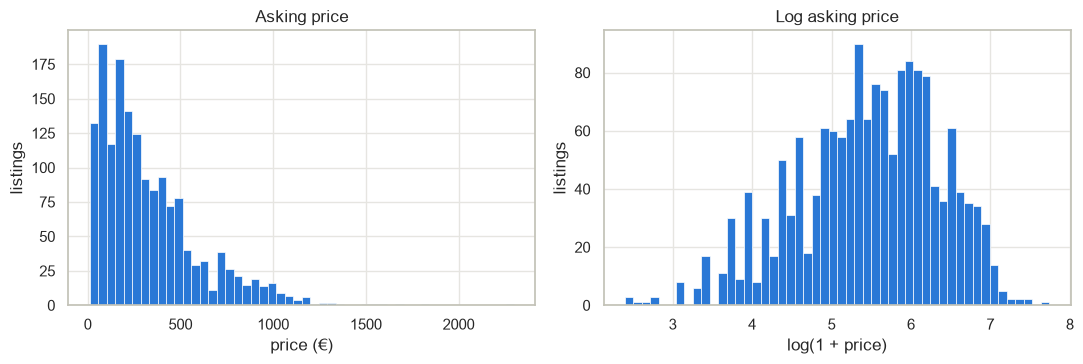

In [2]:
log_price = np.log1p(df["price_eur"])
print(f"median {df['price_eur'].median():.0f} €, mean {df['price_eur'].mean():.0f} €, range {df['price_eur'].min()}–{df['price_eur'].max()} €")
print(f"skewness: price {df['price_eur'].skew():.2f}, log price {log_price.skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df["price_eur"], bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set(title="Asking price", xlabel="price (€)", ylabel="listings")
axes[1].hist(log_price, bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
axes[1].set(title="Log asking price", xlabel="log(1 + price)", ylabel="listings")
plt.tight_layout()
plt.show()

**Takeaway:** prices are strongly right-skewed (skewness 1.57): the middle half of listings ask 130–450 €, while 5 listings (the newest Pro and Pro Max) ask over 1,500 €. On a log scale the distribution is close to symmetric (−0.46). The sections below also show that inputs move prices by a *percentage* (damage −22%, retailers +22%), and a log target turns percentage effects into constant ones that models learn more easily.

**Decision for step 15: train on log1p(price)** and convert predictions back with expm1. This also makes RMSLE the natural error measure, as planned in the ML plan.

## 3. Outliers (step 10)

**What:** the listings furthest from the typical price for their model and storage, in both directions.
**Why:** an extreme price is either an error (fix it in cleaning) or a real asking price (keep it). The model should learn from real prices only.

In [3]:
cols = ["exact_model", "storage_gb", "condition", "seller_type", "price_eur", "rel_price"]
extremes = df.dropna(subset=["rel_price"]).sort_values("rel_price")
print("Cheapest relative to the same phone:")
display(extremes[cols].head(8).round(2))
print("Most expensive relative to the same phone:")
display(extremes[cols].tail(8).round(2))

Cheapest relative to the same phone:


,exact_model,storage_gb,condition,seller_type,price_eur,rel_price
548,iPhone 12,64.0,Vaatii korjausta,private,20,0.14
168,iPhone 12,128.0,Vaatii korjausta,private,35,0.21
316,iPhone 11,128.0,Kohtalainen,private,30,0.21
18,iPhone 12,64.0,Vaatii korjausta,private,30,0.21
663,iPhone 16 Pro,128.0,Vaatii korjausta,private,150,0.22
824,iPhone 11,64.0,Vaatii korjausta,private,30,0.23
1,iPhone 12,128.0,Vaatii korjausta,private,40,0.24
1542,iPhone SE,64.0,Kohtalainen,private,20,0.25


Most expensive relative to the same phone:


,exact_model,storage_gb,condition,seller_type,price_eur,rel_price
1595,iPhone SE (2nd gen),64.0,Kuin uusi,retailer,199,2.49
1587,iPhone XS,64.0,NaN,retailer,189,2.52
1366,iPhone 8 Plus,64.0,Kuin uusi,private,200,2.86
1522,iPhone 12,64.0,Hyvä,retailer,440,3.14
1203,iPhone XR,128.0,Kuin uusi,private,299,3.74
1261,iPhone 11 Pro Max,64.0,Kuin uusi,retailer,820,4.22
1252,iPhone 11 Pro Max,64.0,Kuin uusi,retailer,820,4.22
1260,iPhone X,256.0,Kuin uusi,retailer,250,5.00


**Takeaway:** the cheapest listings are all private sellers with phones in *needs repair* or *fair* condition, e.g. "Rikkinäinen iphone 12" (broken iPhone 12): real listings of broken phones. The most expensive are mostly retailers (warranty, "ALE", Apple part numbers such as "(MGJ83)") plus two private *like new* phones asking far above similar ads: real asking prices, just ambitious ones. The iPhone X 256 GB at 5× typical is a retailer price compared with a handful of cheap private listings.

**Decision: keep them all.** They are genuine asking prices, which is exactly what we predict, and the log target limits how much they pull on a model.

## 4. Price vs each input (step 11)

### 4.1 Phone model: launch year and product line

**What:** price by launch year, and by product line (base, Mini, Plus, Pro, Pro Max, …).
**Why:** the model is the main price driver. Launch year and product line are two ways to describe it that the modelling steps can compare with the model name itself.

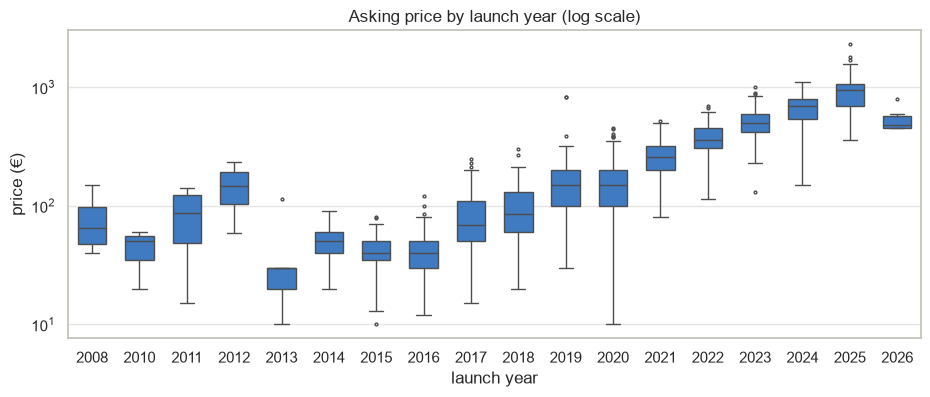

Phones launched 2020 or later: median price by product line


,median,size
exact_model,,
SE,85.0,65
Mini,190.0,68
base / other,299.0,514
Plus,430.0,32
Pro,450.0,266
Pro Max,650.0,225


In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=df, x="release_year", y="price_eur", color=BLUE, width=0.6, fliersize=2, linewidth=1, ax=ax)
ax.set_yscale("log")
ax.set(title="Asking price by launch year (log scale)", xlabel="launch year", ylabel="price (€)")
plt.show()

def line(model):
    if model.startswith("iPhone SE"):
        return "SE"
    for name in ("Pro Max", "Pro", "Plus", "Mini"):
        if model.endswith(name):
            return name
    return "base / other"

recent = df[df["release_year"] >= 2020]
print("Phones launched 2020 or later: median price by product line")
display(recent.groupby(recent["exact_model"].map(line))["price_eur"].agg(["median", "size"]).sort_values("median"))

**Takeaway:** from 2017 on, price rises steadily with launch year: on the log scale, roughly the same percentage per year. Phones launched **before 2017 don't follow the trend**: they have few listings (99) and 80% of them ask 25–80 €, whatever their age. Among phones launched in 2020 or later, the product line orders prices clearly: SE 85 € < Mini 190 € < base 299 € < Plus 430 € ≈ Pro 450 € < Pro Max 650 €.

**For the modelling steps:** the phone model can be described either by its name (51 categories) or by launch year + product line (fewer, shared across models). Both are candidates, compared in the feature check (step 22). The pre-2017 break means a straight-line year effect won't fit old phones well; tree models can bend around it, a linear model can't.

### 4.2 Storage

**What:** median price by storage for the four most common models.
**Why:** storage should raise the price within the same model. How much each doubling adds tells us whether storage should enter a model as GB or on a log scale.

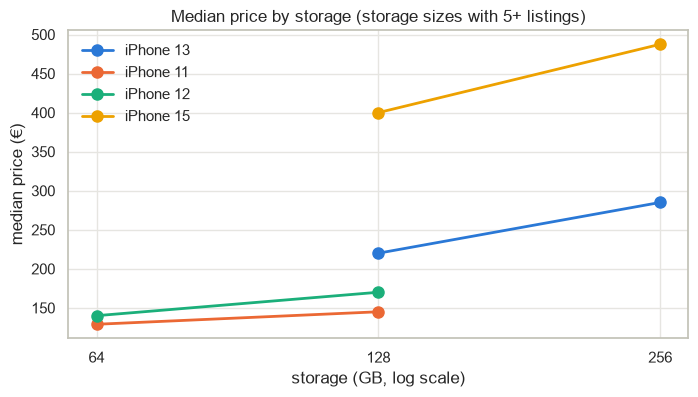

Median price (listings) by storage for the four most common models:


storage_gb,64.0,128.0,256.0,512.0
exact_model,,,,
iPhone 11,129 € (98),145 € (24),150 € (3),NaN
iPhone 12,140 € (70),170 € (27),130 € (3),NaN
iPhone 13,160 € (1),220 € (131),285 € (22),324 € (2)
iPhone 15,NaN,400 € (71),488 € (8),NaN


In [5]:
top4 = df["exact_model"].value_counts().index[:4]
fig, ax = plt.subplots(figsize=(8, 4))
for model, colour in zip(top4, [BLUE, ORANGE, AQUA, YELLOW]):
    m = df[df["exact_model"] == model].groupby("storage_gb")["price_eur"].agg(["median", "size"])
    m = m[m["size"] >= 5]  # skip storage sizes with too few listings to trust the median
    ax.plot(m.index, m["median"], marker="o", markersize=8, linewidth=2, color=colour, label=model)
ax.set_xscale("log", base=2)
ax.set_xticks([64, 128, 256], labels=["64", "128", "256"])
ax.set(title="Median price by storage (storage sizes with 5+ listings)", xlabel="storage (GB, log scale)", ylabel="median price (€)")
ax.legend(frameon=False)
plt.show()

print("Median price (listings) by storage for the four most common models:")
cells = df[df["exact_model"].isin(top4)].groupby(["exact_model", "storage_gb"])["price_eur"].agg(["median", "size"])
display(cells.apply(lambda r: f"{r['median']:.0f} € ({r['size']:.0f})", axis=1).unstack())

**Takeaway:** within the same model, one storage doubling adds roughly 10–30%: iPhone 11 +12% (64 → 128 GB), iPhone 12 +21% (64 → 128), iPhone 13 +30% (128 → 256), iPhone 15 +22% (128 → 256). The step is similar per *doubling*, not per GB, and bigger for newer phones. Several model + storage combinations have only a handful of listings (e.g. iPhone 13 64 GB: 1 listing), which is why the chart skips them.

**Decision for step 16: storage enters as log2(GB)** (64 → 6, 128 → 7, 256 → 8), so each doubling is one equal step. The larger effect on newer phones is an interaction with launch year, which tree models can pick up on their own.

### 4.3 Condition

**What:** relative price for each of Tori's five condition levels.
**Why:** condition should matter a lot. We also need to see whether the levels are in order and evenly spaced, which decides how to encode them (step 18).

,median,count
Vaatii korjausta (needs repair),0.40,27
Kohtalainen (fair),0.72,93
Hyvä (good),0.98,673
Kuin uusi (like new),1.05,507
Uusi (new),1.05,73


missing condition: median relative price 1.03 (49 listings)


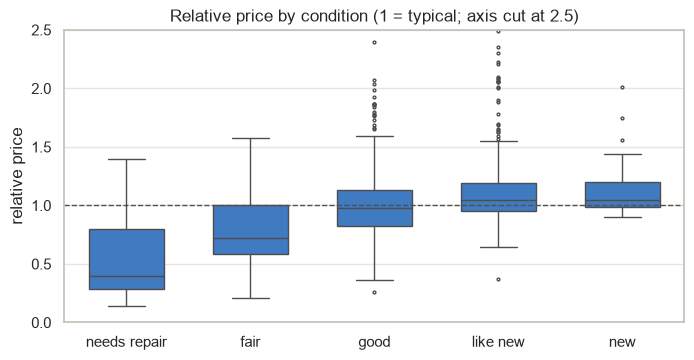

In [6]:
order = ["Vaatii korjausta", "Kohtalainen", "Hyvä", "Kuin uusi", "Uusi"]
english = {"Vaatii korjausta": "needs repair", "Kohtalainen": "fair", "Hyvä": "good", "Kuin uusi": "like new", "Uusi": "new"}
summary = df.groupby("condition")["rel_price"].agg(["median", "count"]).loc[order]
summary.index = [f"{c} ({english[c]})" for c in order]
display(summary.round(2))
print(f"missing condition: median relative price {df.loc[df['condition'].isna(), 'rel_price'].median():.2f} "
      f"({df['condition'].isna().sum()} listings)")

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=df, x="condition", y="rel_price", order=order, color=BLUE, width=0.6, fliersize=2, linewidth=1, ax=ax)
ax.axhline(1, color="#52514e", linewidth=1, linestyle="--")
ax.set_xticks(range(5), labels=[english[c] for c in order])
ax.set(title="Relative price by condition (1 = typical; axis cut at 2.5)", xlabel="", ylabel="relative price", ylim=(0, 2.5))
plt.show()

**Takeaway:** the five levels are clearly ordered: needs repair 0.40, fair 0.72, good 0.98, like new 1.05, new 1.05 (1 = typical price for that phone). But the steps are **uneven**: the big drops are at the bottom, and *new* asks no more than *like new*. The 49 listings with no condition (mostly retailers) price like typical ones (1.03).

**For step 18:** an ordinal rank (0–4) keeps the order and suits tree models. For a linear model, the uneven steps mean one column per level may fit better. Both encodings are candidates. Missing condition is filled inside the pipeline with a was-missing flag.

### 4.4 Seller type

**What:** retailer vs private prices, first raw, then for the same model and storage.
**Why:** retailers look much more expensive in the raw numbers, but they also sell newer phones. The relative price separates the two.

In [7]:
display(df.groupby("seller_type").agg(listings=("price_eur", "size"), median_price=("price_eur", "median"),
                                      median_launch_year=("release_year", "median"), median_rel_price=("rel_price", "median")).round(2))

,listings,median_price,median_launch_year,median_rel_price
seller_type,,,,
private,1265,220.0,2021.0,0.97
retailer,337,340.0,2021.0,1.18


**Takeaway:** the raw medians suggest retailers ask 55% more (340 € vs 220 €). But both sell phones of the same median launch year (2021), and for the **same model and storage retailers ask about 22% more** (1.18 vs 0.97). The rest of the raw gap comes from *which* phones they sell (more storage, pricier variants).

Seller type is a strong candidate input, and it's also one of the two groups in the fairness check.

### 4.5 Battery health

**What:** relative price by battery band, with "not mentioned" as its own band.
**Why:** battery health is half missing (section 6). The bands show whether it matters when given, and whether "not mentioned" prices like a bad battery or like an average one.

In [8]:
df["battery_band"] = pd.cut(df["battery_pct"], bins=[0, 79, 89, 100], labels=["under 80%", "80–89%", "90–100%"]).astype(object)
df["battery_band"] = df["battery_band"].where(df["battery_pct"].notna(), "not mentioned")
bands = ["under 80%", "80–89%", "90–100%", "not mentioned"]
display(df.groupby("battery_band")["rel_price"].agg(["median", "count"]).loc[bands].round(2))

,median,count
battery_band,,
under 80%,0.86,167
80–89%,1.00,285
90–100%,1.05,310
not mentioned,1.00,655


**Takeaway:** battery matters when it's stated: under 80% asks 14% below typical, 90–100% about 5% above. Ads that **don't mention battery price exactly like typical ones (1.00)**, the same as 80–89%. So "not mentioned" does not behave like a hidden bad battery (section 6 looks at why it's missing).

**Decision for step 17: battery enters as bands, with "not mentioned" as its own band.** No values are invented for the 49% of ads that don't state it. Whether it earns its place is decided in the feature check.

### 4.6 Things mentioned in the ad, and shipping

**What:** how much higher or lower the relative price is when an ad mentions damage, warranty, the box or a receipt, or offers shipping.
**Why:** these flags were extracted from the ad text in cleaning. The ones with no visible effect are candidates to drop in the feature check (step 22).

,share of ads,median with,median without,difference
flag,,,,
damage,10%,0.78,1.00,-22%
warranty,21%,1.09,0.98,+11%
box,13%,1.00,1.00,+0%
receipt,4%,1.00,1.00,+0%
shipping offered,38%,0.98,1.01,-3%


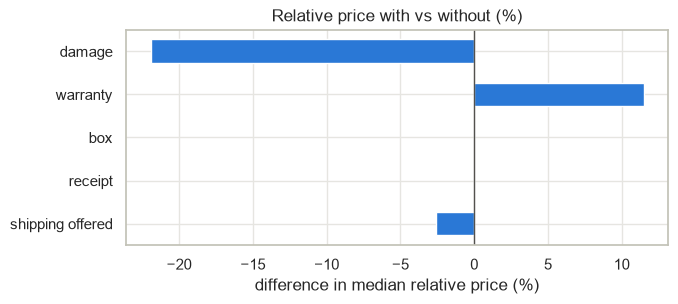

Share of ads mentioning warranty, by seller type:


seller_type
private     0.06
retailer    0.74
Name: mentions_warranty, dtype: float64

Median relative price by seller type and warranty mention:


mentions_warranty,False,True
seller_type,,
private,0.96,1.00
retailer,1.35,1.13


In [9]:
flags = {"mentions_damage": "damage", "mentions_warranty": "warranty", "mentions_box": "box",
         "mentions_receipt": "receipt", "shipping_available": "shipping offered"}
rows = []
for col, label in flags.items():
    with_it, without = df.loc[df[col], "rel_price"], df.loc[~df[col], "rel_price"]
    rows.append({"flag": label, "share of ads": df[col].mean(), "median with": with_it.median(),
                 "median without": without.median(), "difference": with_it.median() / without.median() - 1})
effects = pd.DataFrame(rows).set_index("flag")
display(effects.style.format({"share of ads": "{:.0%}", "median with": "{:.2f}", "median without": "{:.2f}", "difference": "{:+.0%}"}))

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(effects.index[::-1], effects["difference"][::-1] * 100, color=BLUE, height=0.55)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set(title="Relative price with vs without (%)", xlabel="difference in median relative price (%)")
plt.show()

print("Share of ads mentioning warranty, by seller type:")
display(df.groupby("seller_type")["mentions_warranty"].mean().round(2))
print("Median relative price by seller type and warranty mention:")
display(df.groupby(["seller_type", "mentions_warranty"])["rel_price"].median().unstack().round(2))

**Takeaway:**
- **Damage:** ads mentioning damage ask 22% below typical. Damage overlaps with condition (about half of *needs repair* and *fair* ads mention it) but also shows up in 8% of *good* ads, so it adds information.
- **Warranty:** looks like +11%, but 74% of retailer ads mention warranty vs 6% of private ones. Among private sellers the difference is only +4% (1.00 vs 0.96), and among retailers it even goes the other way. Most of the "warranty effect" is seller type.
- **Box, receipt:** no difference at all.
- **Shipping:** −3%, small.

**For the feature check:** damage is a strong candidate; warranty mostly repeats seller type; box, receipt and shipping are likely to drop out. They are tested there with cross-validation, not dropped here.

### 4.7 Region

**What:** relative price by region, for all sellers and for private sellers only, next to each region's share of retailers.
**Why:** region was the team's open question ("?"). If regional differences disappear once retailers are left out, region is mostly a stand-in for seller type.

In [10]:
private = df[df["seller_type"] == "private"]
regions = pd.DataFrame({
    "listings": df["region"].value_counts(),
    "retailer share": df.groupby("region")["seller_type"].apply(lambda s: (s == "retailer").mean()),
    "median rel price (all)": df.groupby("region")["rel_price"].median(),
    "median rel price (private only)": private.groupby("region")["rel_price"].median(),
}).sort_values("listings", ascending=False)
display(regions.style.format({"retailer share": "{:.0%}", "median rel price (all)": "{:.2f}", "median rel price (private only)": "{:.2f}"}))

,listings,retailer share,median rel price (all),median rel price (private only)
region,,,,
Uusimaa,744,27%,1.00,0.97
Pirkanmaa,162,18%,1.00,0.95
Varsinais-Suomi,155,18%,1.00,0.98
Pohjanmaa,75,75%,1.19,0.78
Pohjois-Pohjanmaa,69,14%,1.00,0.95
Keski-Suomi,61,0%,0.95,0.95
Päijät-Häme,54,0%,1.04,1.04
Pohjois-Savo,37,0%,0.95,0.95
Satakunta,36,0%,0.93,0.93


**Takeaway:** across all sellers, Pohjanmaa looks 19% above typical, but 75% of its listings come from retailers. Among its private sellers it's actually 22% *below* (0.78, from only 19 listings). Among private sellers, most regions sit within about ±5% of the overall 0.97; the bigger gaps are regions with few listings (Kymenlaakso 0.85 from 36, Keski-Pohjanmaa 0.68 from 3).

**Regional differences are mostly seller mix plus small-sample noise.** This answers the team's "?": region is a weak candidate, tested in the feature check. It stays in the data either way, because the fairness audit checks errors by region.

## 5. Overlap between inputs (step 12)

**What:** how the numeric inputs move together (Spearman correlation), and which columns are fully determined by another.
**Why:** inputs that carry the same information make linear-model coefficients unstable and hard to interpret. Tree models mostly don't mind, so this informs, but doesn't decide, the feature check.

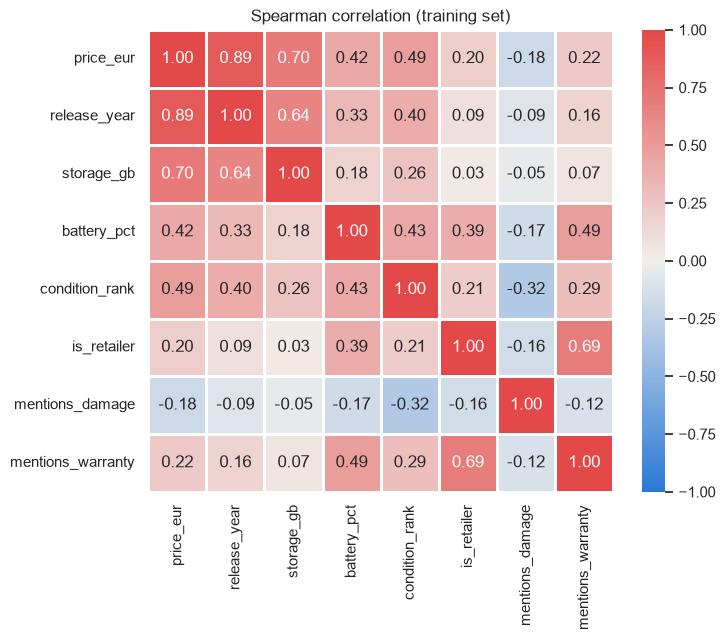

release_year: at most 1 value per exact_model -> determined by the model
model_group: at most 1 value per exact_model -> determined by the model


In [11]:
cols = ["price_eur", "release_year", "storage_gb", "battery_pct", "condition_rank", "is_retailer", "mentions_damage", "mentions_warranty"]
numeric = df.assign(condition_rank=df["condition"].map({c: i for i, c in enumerate(order)}),
                    is_retailer=df["seller_type"].eq("retailer"))[cols].astype(float)
corr = numeric.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=BLUE_GRAY_RED, center=0, vmin=-1, vmax=1, linewidths=1, linecolor="white", ax=ax)
ax.set_title("Spearman correlation (training set)")
plt.show()

# Columns fully determined by the exact model
for col in ["release_year", "model_group"]:
    values_per_model = df.groupby("exact_model")[col].nunique().max()
    print(f"{col}: at most {values_per_model} value per exact_model -> determined by the model")

**Takeaway:** price moves most with launch year (0.89), storage (0.70) and condition (0.49). Overlaps to keep in mind:
- launch year and storage (0.64): newer phones come with more storage
- retailer and warranty (0.69), and battery and warranty (0.49): retailers state both
- condition and damage (−0.32)

`release_year` and `model_group` are **fully determined by `exact_model`**, so no model should get the model name together with either of them: pick one description of the phone model.

**For the modelling steps:** these overlaps matter for plain linear regression (unstable, hard-to-read coefficients) and for interpreting results. Tree models mostly don't mind. The feature check measures what each input adds on top of the others.

## 6. Missing values (step 13)

**What:** which inputs are missing, and whether *missing* is random or tells us something.
**Why:** the right way to handle a missing value (fill it, flag it, or treat "not given" as its own category) depends on why it's missing.

In [12]:
missing = df[["storage_gb", "condition", "battery_pct"]].isna()
display(pd.DataFrame({"missing": missing.sum(), "share": missing.mean().round(3)}))

print("Share of ads that don't mention battery:")
by_year = df.groupby(pd.cut(df["release_year"], [2000, 2017, 2020, 2022, 2026], labels=["up to 2017", "2018–20", "2021–22", "2023–26"]), observed=True)
display(pd.DataFrame({
    "by launch year": by_year["battery_pct"].apply(lambda s: s.isna().mean()),
}).round(2))
display(df.groupby("condition")["battery_pct"].apply(lambda s: s.isna().mean()).loc[order].rename("by condition").round(2))
display(df.groupby("seller_type")["battery_pct"].apply(lambda s: s.isna().mean()).rename("by seller type").round(2))

print("Missing condition by seller type:")
display(df.groupby("seller_type")["condition"].apply(lambda s: s.isna().mean()).round(3))

,missing,share
storage_gb,58,0.036
condition,49,0.031
battery_pct,777,0.485


Share of ads that don't mention battery:


,by launch year
release_year,
up to 2017,0.65
2018–20,0.44
2021–22,0.43
2023–26,0.53


condition
Vaatii korjausta    0.81
Kohtalainen         0.52
Hyvä                0.49
Kuin uusi           0.43
Uusi                0.71
Name: by condition, dtype: float64

seller_type
private     0.52
retailer    0.35
Name: by seller type, dtype: float64

Missing condition by seller type:


seller_type
private     0.019
retailer    0.074
Name: condition, dtype: float64

**Takeaway:** only battery is missing often (49%), and not at random. It's missing most for **old phones** (65%), **brand-new** phones (71%: a new phone's battery is obviously fine) and **broken** ones (81%: battery is beside the point), and more for private sellers (52%) than retailers (35%). Combined with section 4.5 (not mentioned = typical price), this points to "not relevant or not checked" rather than "hiding a bad battery".

Storage (4%) and condition (3%) are rarely missing. Missing condition is mostly retailers (7% of their ads vs 2% for private sellers).

**Decisions for step 17:** battery keeps "not mentioned" as its own band. Storage and condition are filled with the median plus a was-missing flag, inside each model's pipeline so the median comes from training folds only.

## 7. Back to cleaning? (step 14)

**What:** a check for anything in sections 2–6 that looks like a data error rather than a real listing, plus the duplicate ads in the training set.
**Why:** errors go back to `preprocess.py`; real listings stay, however unusual.

In [13]:
sizes = df["relisting_group"].value_counts()
print(f"ads posted more than once: {(sizes > 1).sum()} ads, {sizes[sizes > 1].sum()} listings "
      f"({sizes[sizes > 1].sum() / len(df):.1%} of the training set)")
copies = df[df["relisting_group"].isin(sizes[sizes > 1].index)]
display(copies.groupby("seller_type").size().rename("listings that are copies"))

ads posted more than once: 22 ads, 49 listings (3.1% of the training set)


seller_type
private      6
retailer    43
Name: listings that are copies, dtype: int64

**Takeaway:** 22 ads appear more than once (49 listings, 3.1% of the training set), almost all retailer templates. The grouped split and grouped cross-validation already keep copies together. Nothing in sections 2–6 looks like a data error: the extreme prices in section 3 are real asking prices.

**Decision: no changes to `preprocess.py`.**

## 8. Summary and decisions

**What drives asking prices (training set, 1,602 listings):** the phone model (launch year and product line) and storage explain most of it. For the same phone, condition (−60% for *needs repair*), seller type (retailers +22%), stated damage (−22%) and a worn battery (−14%) move prices further. Box, receipt, shipping and region show little or nothing once seller type is accounted for.

**Decisions for the next steps**

| Step | Decision | Evidence |
|:--|:--|:--|
| 14 Cleaning | No changes needed | Sections 3, 7 |
| 15 Target | Train on log1p(price), score with RMSLE | Section 2 |
| 16 Phone model | Two candidate descriptions: model name, or launch year + product line. Never both | Sections 4.1, 5 |
| 16 Storage | log2(GB), so each doubling is one step | Section 4.2 |
| 17 Battery | Bands, with "not mentioned" as its own band | Sections 4.5, 6 |
| 17 Storage, condition missing | Median + was-missing flag, inside the pipeline | Section 6 |
| 18 Condition | Ordinal rank (0–4); one column per level also tested for the linear model | Section 4.3 |

**Candidates for the feature check (step 22)**

| Likely to help | Doubtful |
|:--|:--|
| Phone model, storage, condition, seller type, damage | Battery, warranty (mostly repeats seller type), region (mostly seller mix), box, receipt, shipping |

The EDA suggests which inputs matter, but doesn't decide: the feature check measures each one with grouped cross-validation on the training set, for every model type.

**Not model inputs** (docs/ml-plan.md): listing age, the raw title and description, `model_group`, `municipality`.